# Instagram Dataset Visualization

This notebook visualizes the distribution of:
1. Number of likes on Instagram posts
2. Number of followers of influencers

In [41]:
import os
import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Dataset

In [ ]:
DATASET_SIZE = "complete"  # Options: "1k" or "10k"
if DATASET_SIZE != "complete":
    print(f"Using dataset size: {DATASET_SIZE}")
    DATASET_SIZE = "10k"  # Options: "1k" or "10k"

    # Paths
    BASE_DIR = Path("/agentic-media-perf")
    DATA_DIR = BASE_DIR / "data" / f"influencer_dataset_subset_{DATASET_SIZE}"
    JSON_DIR = DATA_DIR / "json_subset"
    ANNOTATION_FILE = DATA_DIR / "subset_annotations.txt"
    INFLUENCER_DATA_PATH = Path("/Influencer brand dataset/users_influencers_SPOD/")
# Paths
BASE_DIR = Path("workdir/agentic-media-perf")
DATA_DIR = Path("/Influencer brand dataset/")
JSON_DIR = DATA_DIR / "json"
ANNOTATION_FILE = DATA_DIR / "post_info.txt"
INFLUENCER_DATA_PATH = Path("Influencer brand dataset/users_influencers_SPOD/")
print(f"Loading dataset: {DATASET_SIZE}")
print(f"Data directory: {DATA_DIR}")
print(f"JSON directory exists: {JSON_DIR.exists()}")
print(f"Annotation file exists: {ANNOTATION_FILE.exists()}")


In [ ]:
# Configuration - change this to use 1k or 10k dataset


print(f"Loading dataset: {DATASET_SIZE}")
print(f"Data directory: {DATA_DIR}")
print(f"JSON directory exists: {JSON_DIR.exists()}")
print(f"Annotation file exists: {ANNOTATION_FILE.exists()}")

In [70]:
def parse_influencer_profile(file_path):
    """Parse influencer profile file to extract follower count."""
    if not file_path.exists():
        return None
    
    with open(file_path, "r", encoding="utf-8") as f:
        line = f.readline().strip()
    
    if not line:
        return None
    
    parts = line.split("\t")
    #print(f"Parsing {file_path}: {parts}")
    if len(parts) < 11:
        return None
    
    try:
        name = parts[0].strip()
        followers_str = parts[1].strip().replace(",", "").replace(".", "")
        category = parts[6].strip()
        
        followers = int(float(followers_str)) if followers_str else 1
        
        return {
            "name": name,
            "followers": followers,
            "category": category
        }
    except Exception as e:
        print(f"Error parsing {file_path}: {e}")
        return None

In [59]:
def parse_annotation_line(line):
    """Parse a line from the annotation file (tab-separated format)."""
    line = line.strip()
    if not line:
        return None
    
    # Split by tab
    parts = line.split('\t')
    
    # Expected format: post_id, influencer_name, sponsor_label, json_filename, [image_files]
    if len(parts) < 4:
        return None
    
    try:
        return {
            "post_id": parts[0],
            "influencer_name": parts[1],
            "sponsor_label": int(parts[2]),
            "json_filename": parts[3],
        }
    except (ValueError, IndexError) as e:
        print(f"Error parsing line: {e}")
        return None

In [71]:
# Load data from annotation file
data = []

with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

print(f"Processing {len(lines)} annotations...")

for i, line in enumerate(lines):
    post_info = parse_annotation_line(line)
    
    if post_info is None:
        continue
    
    json_file = JSON_DIR / post_info["json_filename"]
    
    if not json_file.exists():
        continue
    
    # Load JSON data to get likes
    try:
        with open(json_file, "r", encoding="utf-8") as f:
            json_content = json.load(f)
        
        if "edge_media_preview_like" in json_content:
            likes = int(json_content["edge_media_preview_like"]["count"])
        else:
            continue
        
        # Load influencer profile
        influencer_file = INFLUENCER_DATA_PATH / post_info["influencer_name"]
        influencer_data = parse_influencer_profile(influencer_file)
        # print(influencer_data)
        if influencer_data is None:
            continue
        
        data.append({
            "post_id": post_info["post_id"],
            "influencer_name": post_info["influencer_name"],
            "likes": likes,
            "followers": influencer_data["followers"],
            "category": influencer_data["category"],
            "sponsor_label": post_info["sponsor_label"]
        })
    
    except Exception as e:
        print(f"Error processing {json_file}: {e}")
        continue
    
    # Progress indicator every 100 lines
    if (i + 1) % 10000 == 0:
        print(f"Processed {i + 1}/{len(lines)} annotations, loaded {len(data)} posts so far...")

# Create DataFrame
df = pd.DataFrame(data)

print(f"\nSuccessfully loaded {len(df)} posts from {len(lines)} annotations")


Processing 1601074 annotations...
Processed 10000/1601074 annotations, loaded 10000 posts so far...
Processed 20000/1601074 annotations, loaded 20000 posts so far...
Processed 30000/1601074 annotations, loaded 29965 posts so far...
Processed 40000/1601074 annotations, loaded 39965 posts so far...
Processed 50000/1601074 annotations, loaded 49965 posts so far...
Processed 60000/1601074 annotations, loaded 59965 posts so far...
Processed 70000/1601074 annotations, loaded 69965 posts so far...
Processed 80000/1601074 annotations, loaded 79965 posts so far...
Processed 90000/1601074 annotations, loaded 89965 posts so far...
Processed 100000/1601074 annotations, loaded 99965 posts so far...
Processed 110000/1601074 annotations, loaded 109965 posts so far...
Processed 120000/1601074 annotations, loaded 119965 posts so far...
Processed 130000/1601074 annotations, loaded 129965 posts so far...
Processed 140000/1601074 annotations, loaded 139965 posts so far...
Processed 150000/1601074 annotati

In [72]:
print(df.head())

  post_id influencer_name  likes  followers                category  \
0       0        alisasia    914      41099  Creators & Celebrities   
1       1        alisasia   1526      41099  Creators & Celebrities   
2       2        alisasia   1243      41099  Creators & Celebrities   
3       3        alisasia   1011      41099  Creators & Celebrities   
4       4        alisasia    886      41099  Creators & Celebrities   

   sponsor_label  
0              1  
1              0  
2              0  
3              0  
4              0  


In [73]:
# Display basic statistics
print("\n=== Dataset Overview ===")
print(f"Total posts: {len(df)}")
print(f"Unique influencers: {df['influencer_name'].nunique()}")
print(f"\nFirst few rows:")
print(df.head())
print("\n=== Basic Statistics ===")
print(df.describe())


=== Dataset Overview ===
Total posts: 1601039
Unique influencers: 38112

First few rows:
  post_id influencer_name  likes  followers                category  \
0       0        alisasia    914      41099  Creators & Celebrities   
1       1        alisasia   1526      41099  Creators & Celebrities   
2       2        alisasia   1243      41099  Creators & Celebrities   
3       3        alisasia   1011      41099  Creators & Celebrities   
4       4        alisasia    886      41099  Creators & Celebrities   

   sponsor_label  
0              1  
1              0  
2              0  
3              0  
4              0  

=== Basic Statistics ===
              likes     followers  sponsor_label
count  1.601039e+06  1.601039e+06   1.601039e+06
mean   4.344875e+03  1.499987e+05   1.384788e-01
std    4.098018e+04  1.349032e+06   3.454020e-01
min    0.000000e+00  1.980000e+02   0.000000e+00
25%    2.190000e+02  8.223000e+03   0.000000e+00
50%    6.620000e+02  2.208400e+04   0.000000e+00


## 2. Visualize Distribution of Likes

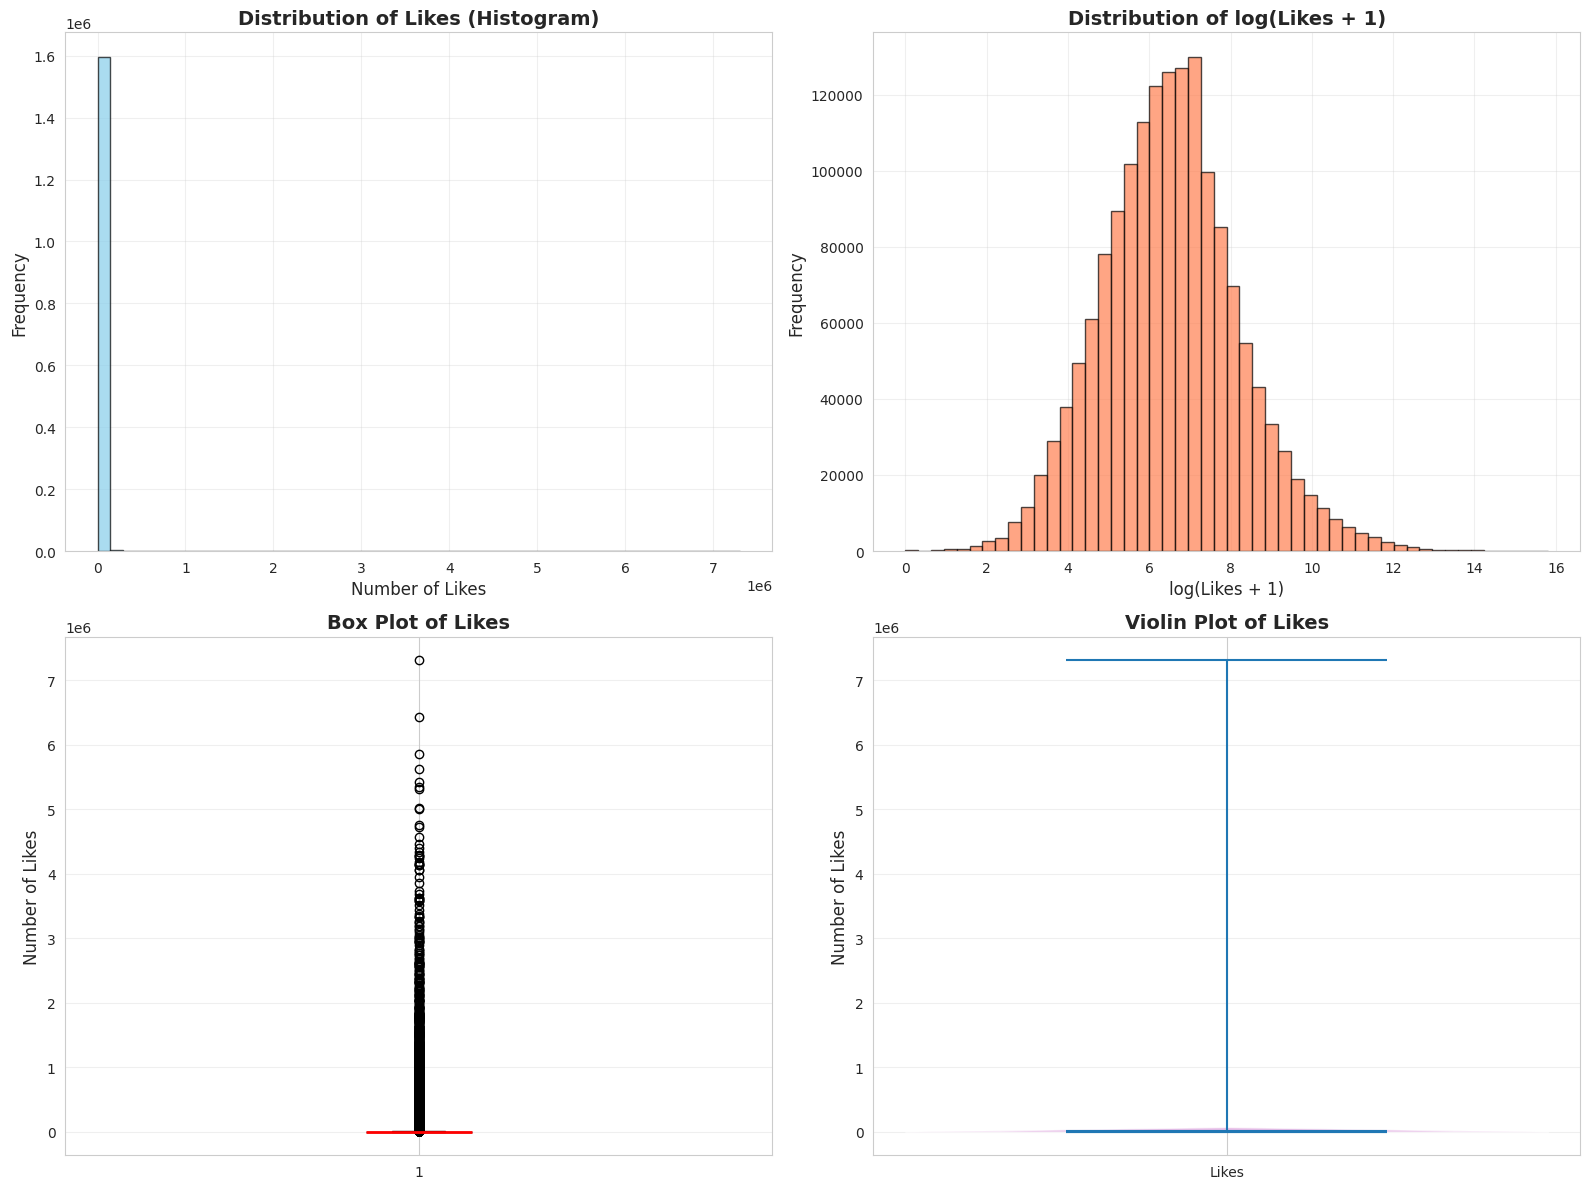


=== Likes Statistics ===
Mean: 4,344.88
Median: 662.00
Std Dev: 40,980.18
Min: 0
Max: 7,309,044
25th Percentile: 219.00
75th Percentile: 1,884.00


In [75]:
# Create figure with multiple subplots for likes distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram of likes
axes[0, 0].hist(df['likes'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Number of Likes', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution of Likes (Histogram)', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# 2. Log-transformed histogram
log_likes = np.log(df['likes'] + 1.0)
axes[0, 1].hist(log_likes, bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('log(Likes + 1)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Distribution of log(Likes + 1)', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. Box plot
axes[1, 0].boxplot(df['likes'], vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightgreen', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_ylabel('Number of Likes', fontsize=12)
axes[1, 0].set_title('Box Plot of Likes', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# 4. Violin plot
parts = axes[1, 1].violinplot([df['likes']], positions=[1], showmeans=True, showmedians=True)
for pc in parts['bodies']:
    pc.set_facecolor('plum')
    pc.set_alpha(0.7)
axes[1, 1].set_ylabel('Number of Likes', fontsize=12)
axes[1, 1].set_title('Violin Plot of Likes', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].set_xticks([1])
axes[1, 1].set_xticklabels(['Likes'])

plt.tight_layout()
plt.savefig(BASE_DIR / 'plots' / f'likes_distribution_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
plt.show()

# Print statistics
print("\n=== Likes Statistics ===")
print(f"Mean: {df['likes'].mean():,.2f}")
print(f"Median: {df['likes'].median():,.2f}")
print(f"Std Dev: {df['likes'].std():,.2f}")
print(f"Min: {df['likes'].min():,}")
print(f"Max: {df['likes'].max():,}")
print(f"25th Percentile: {df['likes'].quantile(0.25):,.2f}")
print(f"75th Percentile: {df['likes'].quantile(0.75):,.2f}")

## 3. Visualize Distribution of Followers

In [76]:
# Get unique influencers (since multiple posts can be from the same influencer)
influencer_df = df.groupby('influencer_name').agg({
    'followers': 'first',
    'category': 'first',
    'post_id': 'count'
}).reset_index()
influencer_df.rename(columns={'post_id': 'num_posts'}, inplace=True)

print(f"\nNumber of unique influencers: {len(influencer_df)}")


Number of unique influencers: 38112


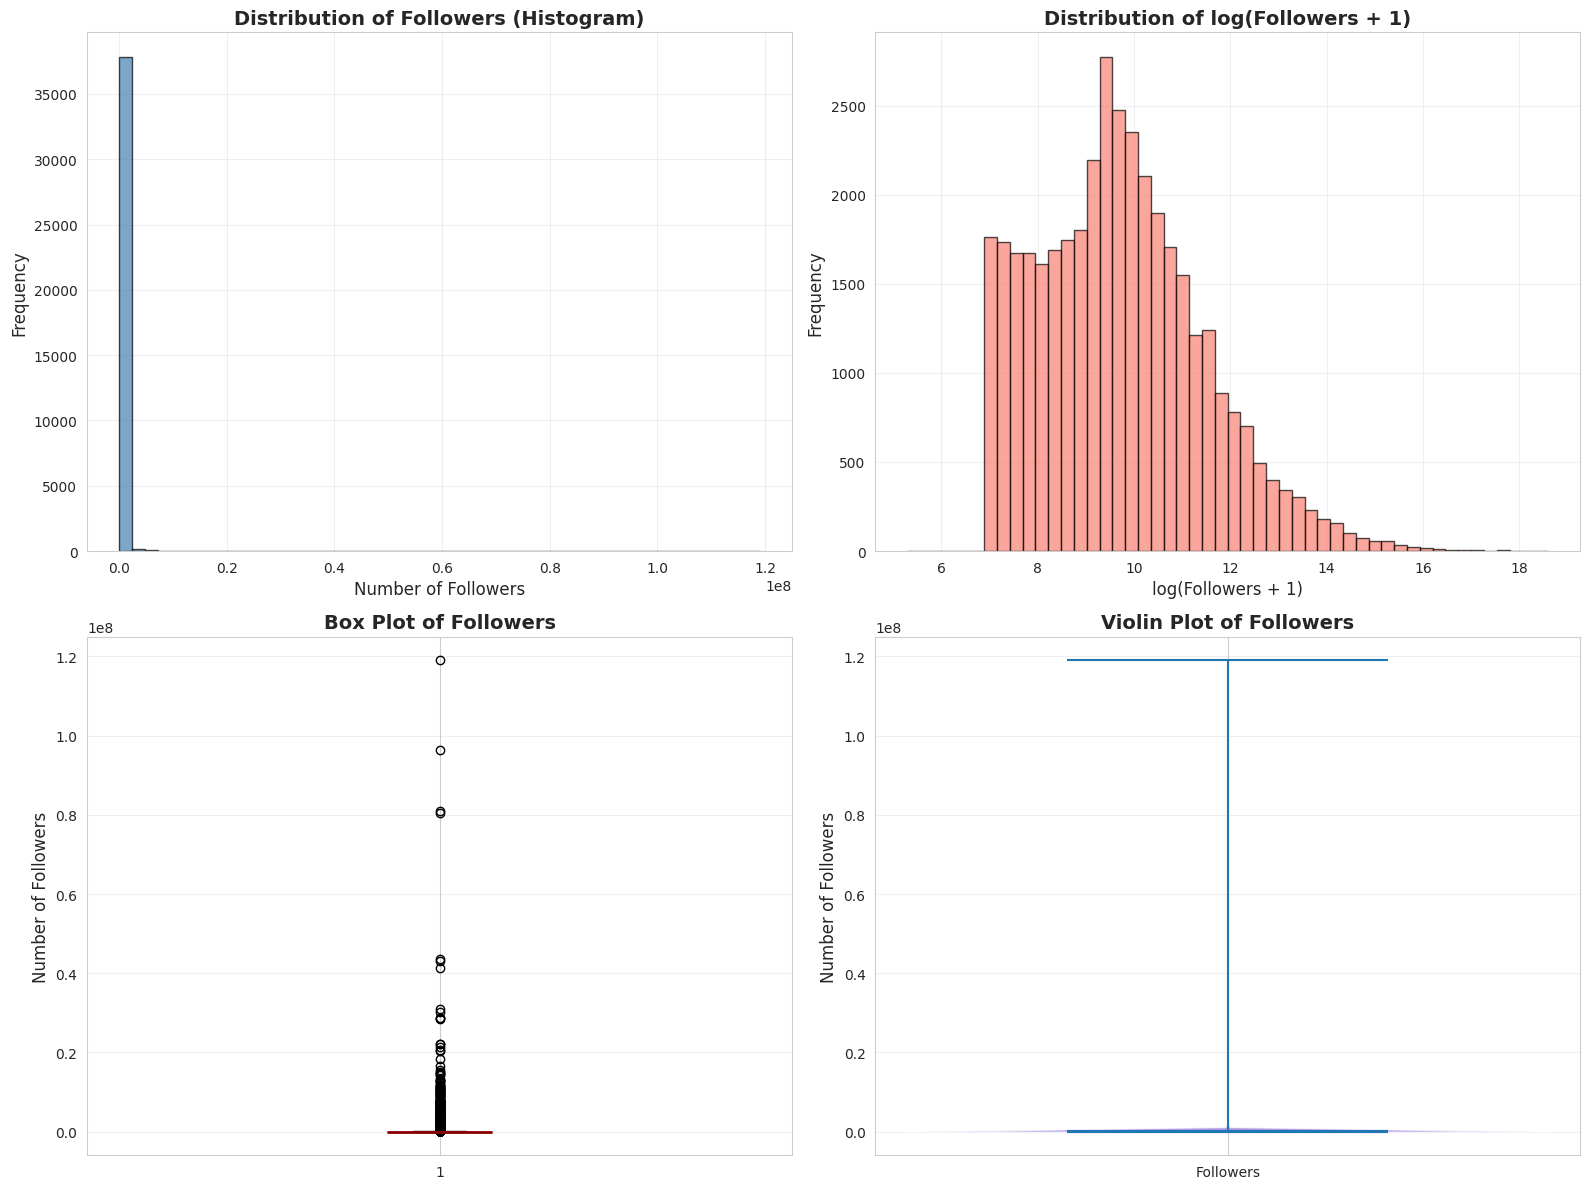


=== Followers Statistics ===
Mean: 127,279.01
Median: 14,641.00
Std Dev: 1,252,174.43
Min: 198
Max: 119,050,781
25th Percentile: 4,382.75
75th Percentile: 48,088.25


In [77]:
# Create figure with multiple subplots for followers distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram of followers
axes[0, 0].hist(influencer_df['followers'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Number of Followers', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution of Followers (Histogram)', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# 2. Log-transformed histogram
log_followers = np.log(influencer_df['followers'] + 1.0)
axes[0, 1].hist(log_followers, bins=50, color='salmon', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('log(Followers + 1)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Distribution of log(Followers + 1)', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. Box plot
axes[1, 0].boxplot(influencer_df['followers'], vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightcoral', alpha=0.7),
                    medianprops=dict(color='darkred', linewidth=2))
axes[1, 0].set_ylabel('Number of Followers', fontsize=12)
axes[1, 0].set_title('Box Plot of Followers', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# 4. Violin plot
parts = axes[1, 1].violinplot([influencer_df['followers']], positions=[1], showmeans=True, showmedians=True)
for pc in parts['bodies']:
    pc.set_facecolor('mediumpurple')
    pc.set_alpha(0.7)
axes[1, 1].set_ylabel('Number of Followers', fontsize=12)
axes[1, 1].set_title('Violin Plot of Followers', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].set_xticks([1])
axes[1, 1].set_xticklabels(['Followers'])

plt.tight_layout()
plt.savefig(BASE_DIR / 'plots' / f'followers_distribution_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
plt.show()

# Print statistics
print("\n=== Followers Statistics ===")
print(f"Mean: {influencer_df['followers'].mean():,.2f}")
print(f"Median: {influencer_df['followers'].median():,.2f}")
print(f"Std Dev: {influencer_df['followers'].std():,.2f}")
print(f"Min: {influencer_df['followers'].min():,}")
print(f"Max: {influencer_df['followers'].max():,}")
print(f"25th Percentile: {influencer_df['followers'].quantile(0.25):,.2f}")
print(f"75th Percentile: {influencer_df['followers'].quantile(0.75):,.2f}")

## 4. Distribution of Posts per Influencer

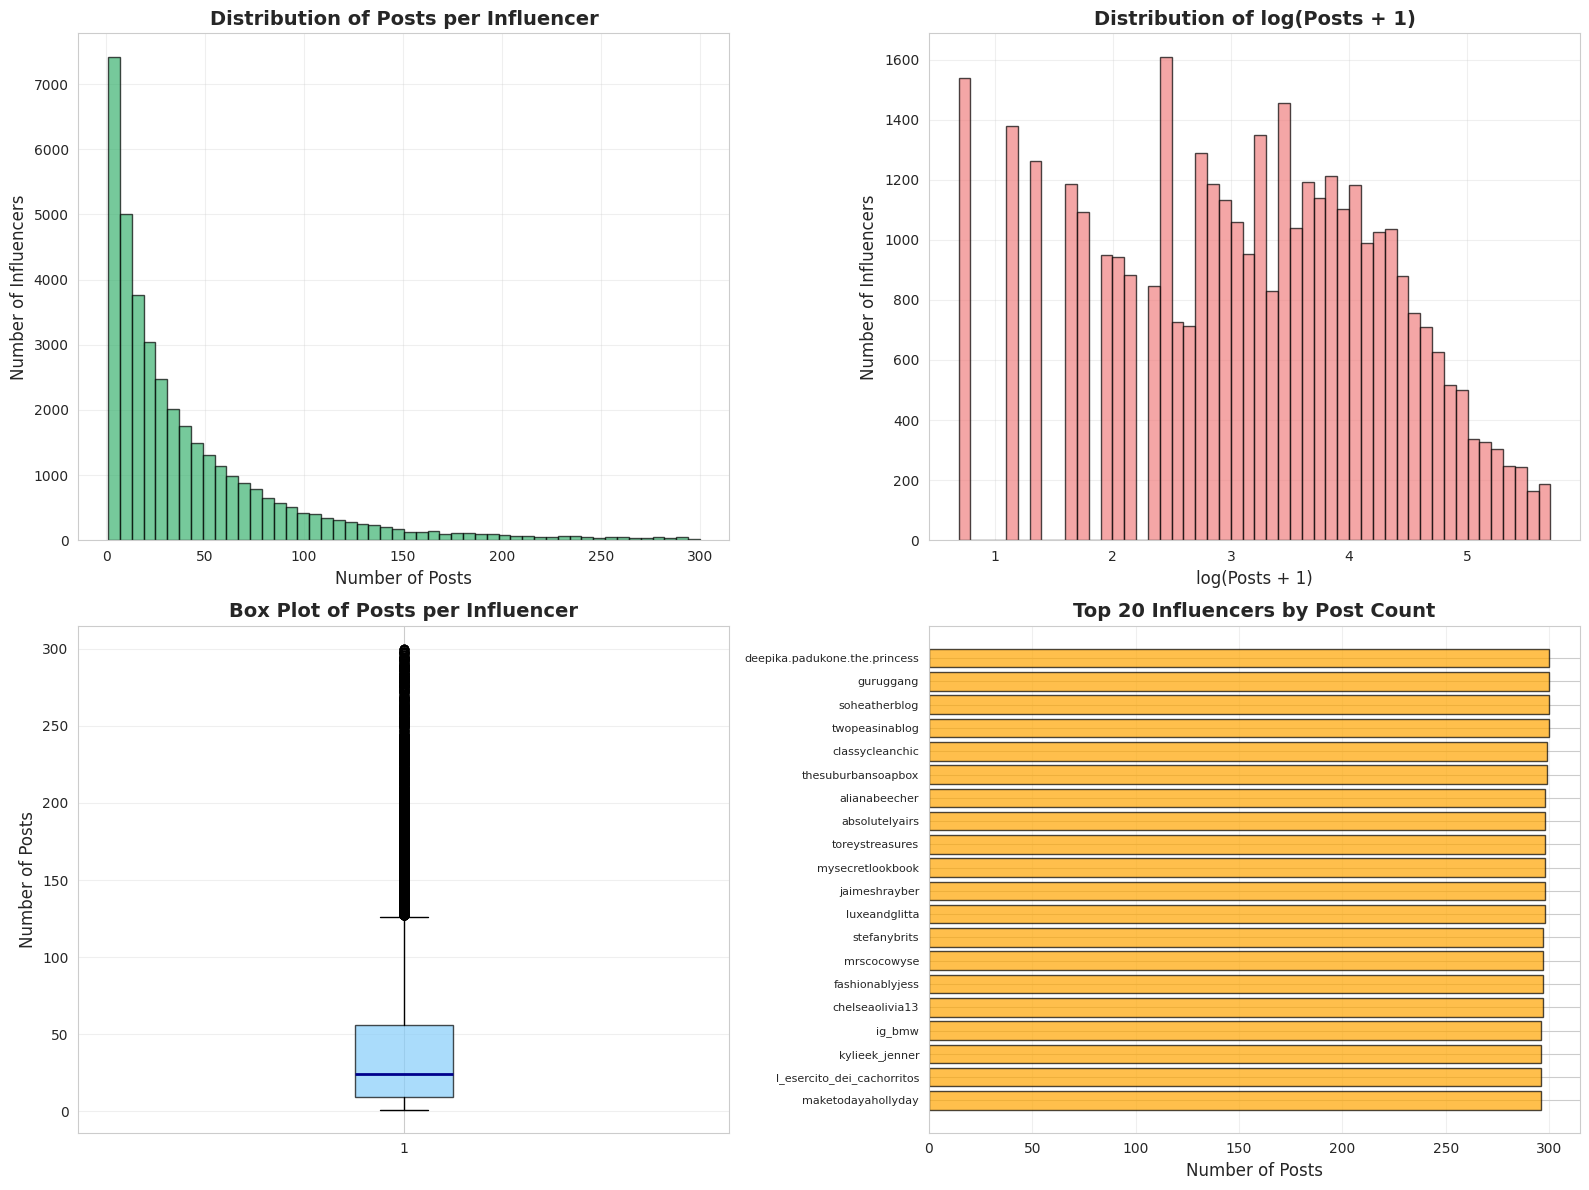


=== Posts per Influencer Statistics ===
Mean: 42.01
Median: 24.00
Std Dev: 49.60
Min: 1
Max: 300
25th Percentile: 9.00
75th Percentile: 56.00

=== Post Count Distribution ===
Influencers with 1 post: 1537 (4.0%)
Influencers with 2 posts: 1380 (3.6%)
Influencers with 3+ posts: 35195 (92.3%)
Influencers with 5+ posts: 32747 (85.9%)


In [78]:
# Create figure with multiple subplots for posts per influencer distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram of posts per influencer
axes[0, 0].hist(influencer_df['num_posts'], bins=50, color='mediumseagreen', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Number of Posts', fontsize=12)
axes[0, 0].set_ylabel('Number of Influencers', fontsize=12)
axes[0, 0].set_title('Distribution of Posts per Influencer', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# 2. Log-transformed histogram
log_posts = np.log(influencer_df['num_posts'] + 1.0)
axes[0, 1].hist(log_posts, bins=50, color='lightcoral', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('log(Posts + 1)', fontsize=12)
axes[0, 1].set_ylabel('Number of Influencers', fontsize=12)
axes[0, 1].set_title('Distribution of log(Posts + 1)', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. Box plot
axes[1, 0].boxplot(influencer_df['num_posts'], vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightskyblue', alpha=0.7),
                    medianprops=dict(color='darkblue', linewidth=2))
axes[1, 0].set_ylabel('Number of Posts', fontsize=12)
axes[1, 0].set_title('Box Plot of Posts per Influencer', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# 4. Bar chart of top 20 influencers by post count
top_posters = influencer_df.nlargest(20, 'num_posts')[['influencer_name', 'num_posts']].sort_values('num_posts', ascending=True)
axes[1, 1].barh(range(len(top_posters)), top_posters['num_posts'], color='orange', edgecolor='black', alpha=0.7)
axes[1, 1].set_yticks(range(len(top_posters)))
axes[1, 1].set_yticklabels(top_posters['influencer_name'], fontsize=8)
axes[1, 1].set_xlabel('Number of Posts', fontsize=12)
axes[1, 1].set_title('Top 20 Influencers by Post Count', fontsize=14, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(BASE_DIR / 'plots' / f'posts_per_influencer_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
plt.show()

# Print statistics
print("\n=== Posts per Influencer Statistics ===")
print(f"Mean: {influencer_df['num_posts'].mean():.2f}")
print(f"Median: {influencer_df['num_posts'].median():.2f}")
print(f"Std Dev: {influencer_df['num_posts'].std():.2f}")
print(f"Min: {influencer_df['num_posts'].min()}")
print(f"Max: {influencer_df['num_posts'].max()}")
print(f"25th Percentile: {influencer_df['num_posts'].quantile(0.25):.2f}")
print(f"75th Percentile: {influencer_df['num_posts'].quantile(0.75):.2f}")

# Show distribution of post counts
post_count_dist = influencer_df['num_posts'].value_counts().sort_index()
print(f"\n=== Post Count Distribution ===")
print(f"Influencers with 1 post: {(influencer_df['num_posts'] == 1).sum()} ({(influencer_df['num_posts'] == 1).sum() / len(influencer_df) * 100:.1f}%)")
print(f"Influencers with 2 posts: {(influencer_df['num_posts'] == 2).sum()} ({(influencer_df['num_posts'] == 2).sum() / len(influencer_df) * 100:.1f}%)")
print(f"Influencers with 3+ posts: {(influencer_df['num_posts'] >= 3).sum()} ({(influencer_df['num_posts'] >= 3).sum() / len(influencer_df) * 100:.1f}%)")
print(f"Influencers with 5+ posts: {(influencer_df['num_posts'] >= 5).sum()} ({(influencer_df['num_posts'] >= 5).sum() / len(influencer_df) * 100:.1f}%)")

## 5. Additional Analysis: Engagement Rate

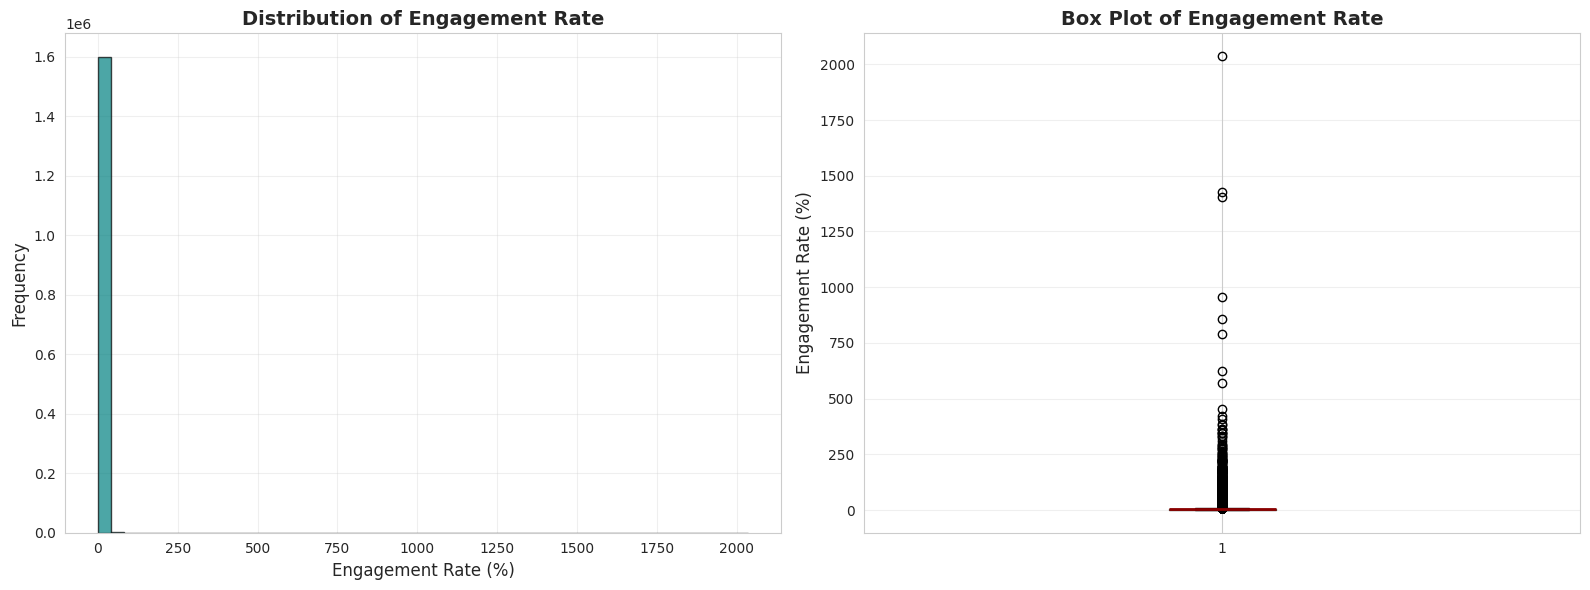


=== Engagement Rate Statistics ===
Mean: 4.2324%
Median: 2.9588%
Std Dev: 5.6138%
Min: 0.0000%
Max: 2037.2819%


In [79]:
# Calculate engagement rate (likes / followers)
df['engagement_rate'] = (df['likes'] / df['followers']) * 100

# Create engagement rate visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
axes[0].hist(df['engagement_rate'], bins=50, color='teal', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Engagement Rate (%)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Distribution of Engagement Rate', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Box plot
axes[1].boxplot(df['engagement_rate'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='gold', alpha=0.7),
                medianprops=dict(color='darkred', linewidth=2))
axes[1].set_ylabel('Engagement Rate (%)', fontsize=12)
axes[1].set_title('Box Plot of Engagement Rate', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(BASE_DIR / 'plots' / f'engagement_rate_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n=== Engagement Rate Statistics ===")
print(f"Mean: {df['engagement_rate'].mean():.4f}%")
print(f"Median: {df['engagement_rate'].median():.4f}%")
print(f"Std Dev: {df['engagement_rate'].std():.4f}%")
print(f"Min: {df['engagement_rate'].min():.4f}%")
print(f"Max: {df['engagement_rate'].max():.4f}%")

## 6. Scatter Plot: Likes vs Followers

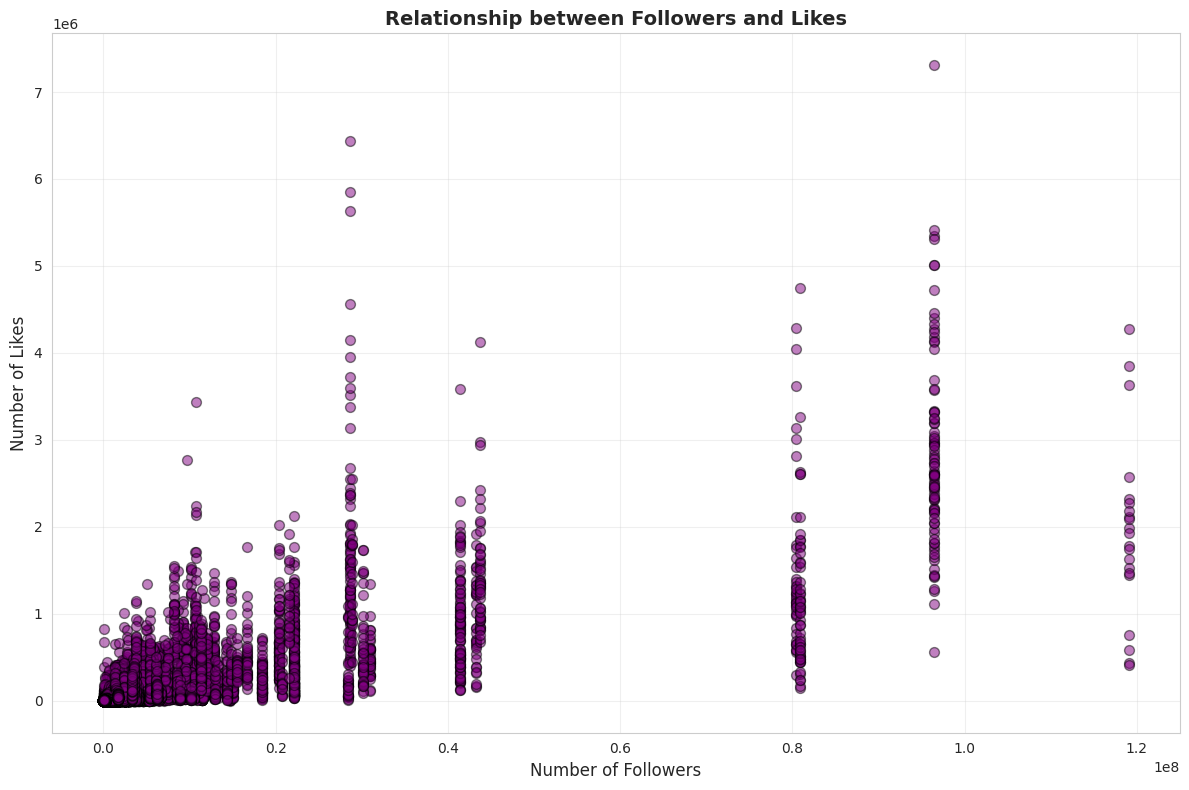


Correlation between likes and followers: 0.7853


In [67]:
# Create scatter plot
plt.figure(figsize=(12, 8))
plt.scatter(df['followers'], df['likes'], alpha=0.5, c='purple', edgecolors='black', s=50)
plt.xlabel('Number of Followers', fontsize=12)
plt.ylabel('Number of Likes', fontsize=12)
plt.title('Relationship between Followers and Likes', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(BASE_DIR / 'plots' / f'likes_vs_followers_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate correlation
correlation = df[['likes', 'followers']].corr().iloc[0, 1]
print(f"\nCorrelation between likes and followers: {correlation:.4f}")

## 7. Category Analysis (if available)


=== Statistics by Category ===
                                              followers                    \
                                                   mean     median  count   
category                                                                    
Auto Dealers                                   74585.40    10741.0     30   
Business & Utility Services                    27623.93     7165.5    288   
Content & Apps                                113131.06    20133.0    131   
Creators & Celebrities                         90339.53    17805.0  24486   
Entities                                       24924.33    10278.0      9   
Food & Personal Goods                          55260.15    18267.0    171   
General Interest                               64435.35    13155.0   1421   
Geography                                      57246.00    57246.0      2   
Government Agencies                            21808.69     4094.0     13   
Grocery & Convenience Stores                

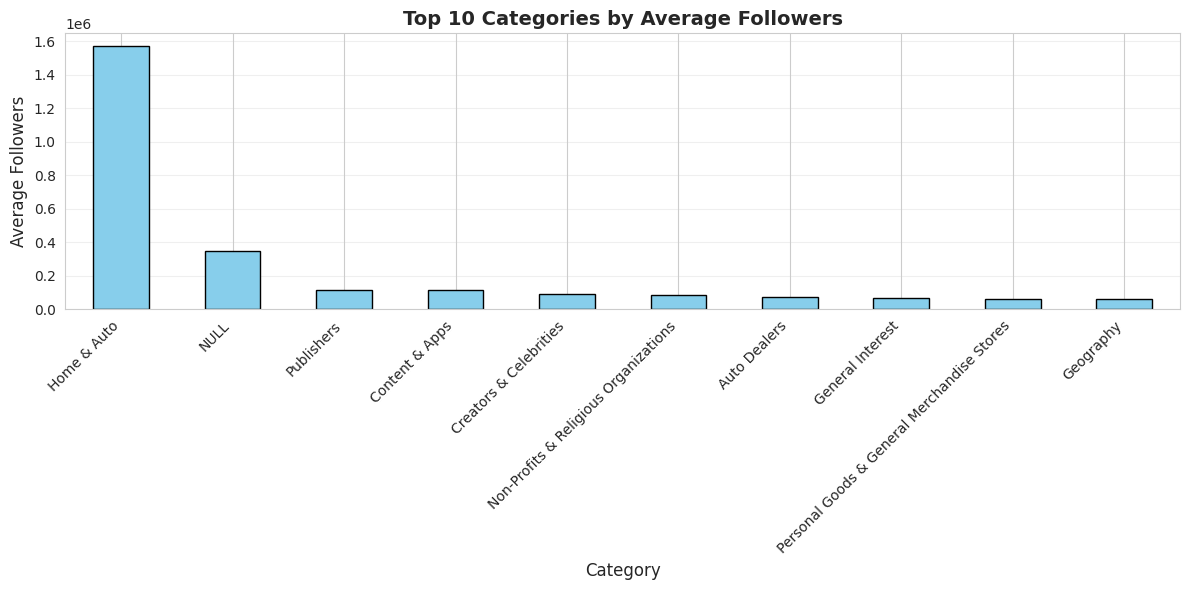

In [80]:
# Analyze by category
if 'category' in influencer_df.columns and influencer_df['category'].notna().any():
    category_stats = influencer_df.groupby('category').agg({
        'followers': ['mean', 'median', 'count'],
        'num_posts': 'sum'
    }).round(2)
    
    print("\n=== Statistics by Category ===")
    print(category_stats)
    
    # Plot top categories by average followers
    top_categories = influencer_df.groupby('category')['followers'].mean().sort_values(ascending=False).head(10)
    
    plt.figure(figsize=(12, 6))
    top_categories.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.xlabel('Category', fontsize=12)
    plt.ylabel('Average Followers', fontsize=12)
    plt.title('Top 10 Categories by Average Followers', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(BASE_DIR / 'plots' / f'top_categories_{DATASET_SIZE}.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("\nNo category information available")

## 8. Summary Statistics Table

In [81]:
# Create summary table
summary = pd.DataFrame({
    'Metric': ['Total Posts', 'Unique Influencers', 'Avg Likes', 'Median Likes', 
               'Avg Followers', 'Median Followers', 'Avg Engagement Rate (%)'],
    'Value': [
        len(df),
        df['influencer_name'].nunique(),
        f"{df['likes'].mean():,.2f}",
        f"{df['likes'].median():,.2f}",
        f"{influencer_df['followers'].mean():,.2f}",
        f"{influencer_df['followers'].median():,.2f}",
        f"{df['engagement_rate'].mean():.4f}"
    ]
})

print("\n=== Dataset Summary ===")
print(summary.to_string(index=False))


=== Dataset Summary ===
                 Metric      Value
            Total Posts    1601039
     Unique Influencers      38112
              Avg Likes   4,344.88
           Median Likes     662.00
          Avg Followers 127,279.01
       Median Followers  14,641.00
Avg Engagement Rate (%)     4.2324
